# Data Preprocessing Using the Titanic Dataset

**Experiment:** Missing-value treatment, duplicate handling, categorical encoding, normalization, and standardization

## Objectives
- Inspect the dataset structure and identify data-quality issues.
- Handle missing values using appropriate strategies.
- Check for and remove duplicate records where present.
- Convert categorical variables into a machine-readable representation.
- Apply Min-Max normalization and standardization to numerical features.
- Compare the data before and after preprocessing and summarize the results.

## Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, and scikit-learn.

## 1. Load the dataset

The experiment uses the Titanic passenger dataset containing passenger attributes and the survival outcome. Identifier-like and free-text columns are retained in the raw dataset for inspection, but are not included in the compact transformed feature set.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, StandardScaler
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["figure.dpi"] = 110

DATA_PATH = "titanic.csv"
df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")
display(df.head())

Dataset shape: 891 rows x 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Inspect structure and data types

The first checks establish the size of the dataset, data types, and basic numerical summaries. This step helps distinguish numerical measurements from categorical variables before selecting preprocessing methods.

In [2]:
print("Column data types:")
display(df.dtypes.rename("dtype").to_frame())
print("Numerical summary:")
display(df.describe(include=[np.number]).T.round(2))

Column data types:


,dtype
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


Numerical summary:


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.00,257.35,1.00,223.50,446.00,668.5,891.00
Survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
Pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
Age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33


## 3. Detect missing values

Missing values are counted and expressed as a percentage of all records. `Age` and `Embarked` can be imputed, while `Cabin` is omitted from the compact model-ready feature set because most entries are missing.

,Missing Count,Missing Percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


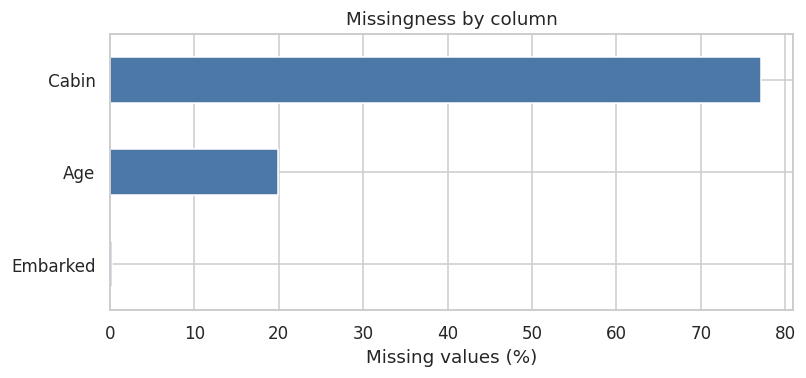

In [3]:
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percent": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Count", ascending=False)
display(missing)

missing_nonzero = missing[missing["Missing Count"] > 0].sort_values("Missing Percent")
ax = missing_nonzero["Missing Percent"].plot(kind="barh", figsize=(7.5, 3.6), color="#4C78A8")
ax.set_xlabel("Missing values (%)")
ax.set_title("Missingness by column")
plt.tight_layout()
plt.show()

## 4. Impute missing values

The median is used for `Age` because it is less sensitive to extreme values than the mean. The most frequent `Embarked` category is used for the two missing entries. The `Cabin` column is excluded from the selected feature set due to its high missingness.

In [4]:
clean = df.copy()
age_median = clean["Age"].median()
embarked_mode = clean["Embarked"].mode(dropna=True)[0]
clean["Age"] = clean["Age"].fillna(age_median)
clean["Embarked"] = clean["Embarked"].fillna(embarked_mode)

print(f"Age median used for imputation: {age_median:.2f}")
print(f"Embarked mode used for imputation: {embarked_mode}")
print("Missing values after imputation:")
display(clean[["Age", "Embarked"]].isna().sum().rename("Remaining missing").to_frame())

Age median used for imputation: 28.00
Embarked mode used for imputation: S
Missing values after imputation:


,Remaining missing
Age,0
Embarked,0


## 5. Detect and remove duplicate records

Exact duplicate rows are counted before removal. Calling `drop_duplicates` makes the procedure explicit and keeps the workflow robust if the input data later contains repeated records.

In [5]:
duplicate_count = int(clean.duplicated().sum())
clean = clean.drop_duplicates().reset_index(drop=True)
print(f"Exact duplicate rows detected: {duplicate_count}")
print(f"Rows after duplicate removal: {len(clean)}")
print(f"Remaining exact duplicates: {int(clean.duplicated().sum())}")

Exact duplicate rows detected: 0
Rows after duplicate removal: 891
Remaining exact duplicates: 0


## 6. Select and prepare features

For a concise preprocessing demonstration, the feature set uses passenger class, sex, age, family counts, fare, and embarkation port. `PassengerId`, `Name`, `Ticket`, and `Cabin` are excluded because they are identifiers, high-cardinality text, or too incomplete for this basic pipeline. `Survived` is kept separately as the target and is not scaled or encoded as an input feature.

In [6]:
feature_columns = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
X = clean[feature_columns].copy()
y = clean["Survived"].copy()

numeric_columns = ["Age", "SibSp", "Parch", "Fare"]
categorical_columns = ["Pclass", "Sex", "Embarked"]
X[categorical_columns] = X[categorical_columns].astype("string")
print("Selected feature matrix:", X.shape)
print("Target distribution:")
display(y.value_counts().rename(index={0:"Did not survive", 1:"Survived"}).to_frame("Passengers"))
display(X.head())

Selected feature matrix: (891, 7)
Target distribution:


,Passengers
Survived,
Did not survive,549
Survived,342


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


## 7. One-hot encode categorical features

One-hot encoding creates binary indicator columns for each observed category. This avoids assigning an artificial numeric order to categories such as sex and embarkation port. The target column is not part of the encoded feature matrix.

In [7]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=int)
encoded_array = encoder.fit_transform(X[categorical_columns])
encoded_names = encoder.get_feature_names_out(categorical_columns)
encoded = pd.DataFrame(encoded_array, columns=encoded_names, index=X.index)
encoded_preview = pd.concat([X[numeric_columns], encoded], axis=1)
print("Categorical columns before encoding:", categorical_columns)
print("Encoded indicator columns:", len(encoded_names))
display(encoded_preview.head().round(2))

Categorical columns before encoding: ['Pclass', 'Sex', 'Embarked']
Encoded indicator columns: 8


,Age,SibSp,Parch,Fare,Pclass_1,Pclass_2,Pclass_3,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,22.0,1,0,7.25,0,0,1,0,1,0,0,1
1,38.0,1,0,71.28,1,0,0,1,0,1,0,0
2,26.0,0,0,7.92,0,0,1,1,0,0,0,1
3,35.0,1,0,53.10,1,0,0,1,0,0,0,1
4,35.0,0,0,8.05,0,0,1,0,1,0,0,1


## 8. Min-Max normalization

Min-Max scaling transforms each selected numerical feature to a range from 0 to 1. It preserves the relative ordering of values, although extreme observations can influence the scaled distribution.

In [8]:
minmax_scaler = MinMaxScaler()
X_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(X[numeric_columns]),
    columns=numeric_columns,
    index=X.index
)
print("Original numerical ranges:")
display(X[numeric_columns].agg(["min", "max"]).T.rename(columns={"min":"Original min", "max":"Original max"}))
print("Ranges after Min-Max normalization:")
display(X_minmax.agg(["min", "max"]).T.rename(columns={"min":"Scaled min", "max":"Scaled max"}).round(3))

Original numerical ranges:


,Original min,Original max
Age,0.42,80.0000
SibSp,0.00,8.0000
Parch,0.00,6.0000
Fare,0.00,512.3292


Ranges after Min-Max normalization:


,Scaled min,Scaled max
Age,0.0,1.0
SibSp,0.0,1.0
Parch,0.0,1.0
Fare,0.0,1.0


## 9. Standardization

Standardization subtracts each feature's mean and divides by its standard deviation. The transformed values should have means near zero and standard deviations near one. Unlike Min-Max scaling, standardized values are not restricted to the interval from zero to one.

In [9]:
standard_scaler = StandardScaler()
X_standard = pd.DataFrame(
    standard_scaler.fit_transform(X[numeric_columns]),
    columns=numeric_columns,
    index=X.index
)
summary = pd.DataFrame({
    "Mean after standardization": X_standard.mean(),
    "Standard deviation": X_standard.std(ddof=0)
})
display(summary.round(3))

,Mean after standardization,Standard deviation
Age,0.0,1.0
SibSp,0.0,1.0
Parch,0.0,1.0
Fare,0.0,1.0


## 10. Compare original and transformed distributions

The following plots compare the raw numerical features with their Min-Max normalized and standardized versions. The scales differ by design, so the plots are used to illustrate transformation effects rather than to compare the absolute magnitude of each feature.

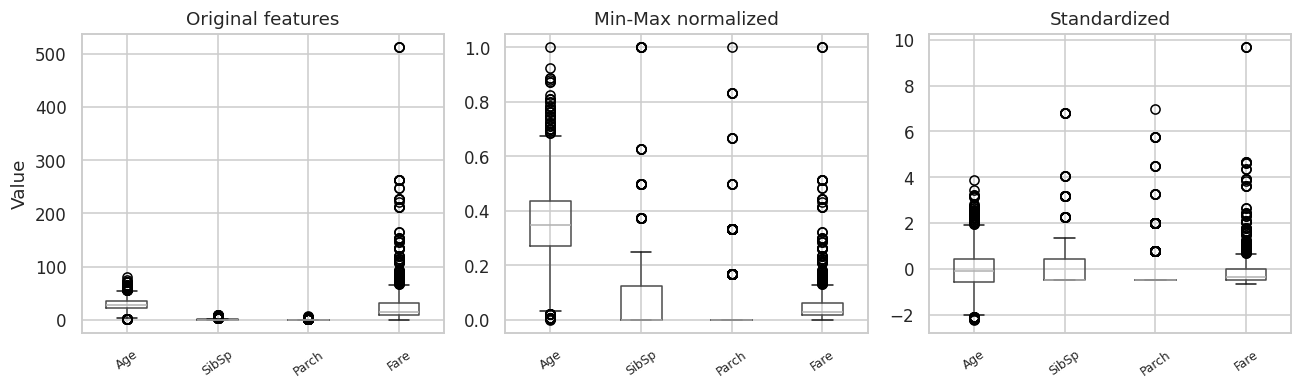

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
X[numeric_columns].boxplot(ax=axes[0], rot=35)
axes[0].set_title("Original features")
axes[0].set_ylabel("Value")
X_minmax.boxplot(ax=axes[1], rot=35)
axes[1].set_title("Min-Max normalized")
X_standard.boxplot(ax=axes[2], rot=35)
axes[2].set_title("Standardized")
for ax in axes:
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

## 11. Assemble the model-ready feature table

The final table combines scaled numerical features with one-hot encoded categorical indicators. This is a demonstration of preprocessing, not a model-training experiment. For predictive evaluation, the encoder and scalers should be fitted only on training data using a pipeline to avoid data leakage.

In [11]:
X_ready = pd.concat([X_minmax, encoded], axis=1)
print("Final transformed feature matrix shape:", X_ready.shape)
print("Target shape:", y.shape)
print("Any missing values in transformed features?", bool(X_ready.isna().any().any()))
print("Any non-finite values in transformed features?", bool((~np.isfinite(X_ready.to_numpy(dtype=float))).any()))
display(X_ready.head().round(3))

Final transformed feature matrix shape: (891, 12)
Target shape: (891,)
Any missing values in transformed features? False
Any non-finite values in transformed features? False


,Age,SibSp,Parch,Fare,Pclass_1,Pclass_2,Pclass_3,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0.271,0.125,0.0,0.014,0,0,1,0,1,0,0,1
1,0.472,0.125,0.0,0.139,1,0,0,1,0,1,0,0
2,0.321,0.000,0.0,0.015,0,0,1,1,0,0,0,1
3,0.435,0.125,0.0,0.104,1,0,0,1,0,0,0,1
4,0.435,0.000,0.0,0.016,0,0,1,0,1,0,0,1


## Results and observations

- Missing values were identified in `Age`, `Cabin`, and `Embarked`.
- `Age` was imputed with its median and `Embarked` with its mode. `Cabin` was excluded from the selected feature set because of extensive missingness.
- Duplicate rows were checked and removed if present. The supplied Titanic dataset contains no exact duplicate rows.
- Categorical predictors were one-hot encoded into binary indicator columns.
- Min-Max normalization mapped selected numerical features to the 0 to 1 range.
- Standardization produced numerical features with means near zero and standard deviations near one.
- The final transformed feature table contained no missing or non-finite values.

## Conclusion

The experiment demonstrated a basic end-to-end preprocessing workflow on the Titanic dataset. Appropriate treatment of missing values, duplicate checks, categorical encoding, normalization, and standardization produced a consistent numerical feature matrix suitable for subsequent modelling. In a real predictive workflow, preprocessing steps should be fitted on training data only and applied to validation or test data without refitting.